# Telco Customer Churn: Exploratory Data Analysis

**Domain:** Telecommunications / Customer Retention  
**Tools:** Python, Pandas, NumPy, SciPy, Matplotlib, Seaborn  

---
## Table of Contents
1. Dataset Selection & Business Context
2. Data Exploration
3. Data Cleaning & Preprocessing
4. Exploratory Data Analysis (statistics, trends, correlations)
5. Data Visualizations
6. Key Insights, Interpretations & Recommendations

## 1. Dataset Selection & Business Context

**Source:** IBM Telco Customer Churn sample dataset (public, hosted on IBM's GitHub: `IBM/telco-customer-churn-on-icp4d`). It is a widely used benchmark, derived from a fictional telecom provider in California with 7,043 customers.

**Business problem.** Acquiring a new customer typically costs far more than retaining an existing one, so telecom providers closely track **churn**, the share of customers who leave in a given period. If we can understand *who* churns and *why*, retention budgets can be aimed at the right customers.

**Analytical objectives**
1. Measure the overall churn rate and the revenue exposed to it.
2. Identify customer attributes (contract, tenure, services, pricing, payment method, demographics) associated with churn.
3. Turn the findings into practical retention recommendations.

**Variables (21 columns, one row per customer)**

| Group | Columns |
|---|---|
| Identity | `customerID` |
| Demographics | `gender`, `SeniorCitizen`, `Partner`, `Dependents` |
| Account | `tenure` (months), `Contract`, `PaperlessBilling`, `PaymentMethod` |
| Services | `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` |
| Charges | `MonthlyCharges`, `TotalCharges` |
| **Target** | `Churn` (Yes = left within the last month) |

**Expected outcome:** a clear profile of high-risk customers, with quantified differences between groups.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 50)

URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
try:
    raw = pd.read_csv(URL)
except Exception:
    raw = pd.read_csv("../data/raw/Telco-Customer-Churn.csv")   # local copy fallback
df = raw.copy()
print("Loaded:", df.shape)
df.head()

Loaded: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Data Exploration

### 2.1 Structure and data types

In [2]:
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}\n")
df.info()

Rows: 7,043 | Columns: 21

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non

**Observation.** `TotalCharges` is stored as `object` (text) although it is a monetary amount. This hints at non-numeric entries, which we investigate below. `SeniorCitizen` is coded 0/1 while all other binary fields use Yes/No, an inconsistency to fix.

### 2.2 Summary statistics

In [3]:
display(df.describe().T)
display(df.describe(include="object").T.drop(columns=["count"]))

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


,unique,top,freq
customerID,7043,7590-VHVEG,1
gender,2,Male,3555
Partner,2,No,3641
Dependents,2,No,4933
PhoneService,2,Yes,6361
MultipleLines,3,No,3390
InternetService,3,Fiber optic,3096
OnlineSecurity,3,No,3498
OnlineBackup,3,No,3088
DeviceProtection,3,No,3095


### 2.3 Missing values, duplicates and hidden problems

In [4]:
# Standard missing values
print("Null values per column (non-zero only):")
print(df.isna().sum()[lambda s: s > 0] if df.isna().sum().sum() else "None detected by isna()")

# Hidden missing values: blank strings / whitespace
blank = df.apply(lambda c: c.astype(str).str.strip().eq("").sum())
print("\nBlank-string entries per column (non-zero only):")
print(blank[blank > 0])

# Duplicates
print("\nFully duplicated rows:", df.duplicated().sum())
print("Duplicated customerID :", df["customerID"].duplicated().sum())

Null values per column (non-zero only):
None detected by isna()

Blank-string entries per column (non-zero only):
TotalCharges    11
dtype: int64

Fully duplicated rows: 0
Duplicated customerID : 0


In [5]:
# Inspect the rows hiding blank TotalCharges
bad = df[df["TotalCharges"].str.strip() == ""]
bad[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


**Observation.** There are no null values or duplicates, but `TotalCharges` hides **11 blank strings**, which is why pandas read the column as text. All 11 customers have `tenure = 0`: they signed up this period and have not yet been billed, so a total of **0** is the logically correct value rather than an imputed average.

### 2.4 Categorical value inspection (consistency check)

In [6]:
cat_cols = df.select_dtypes("object").columns.drop(["customerID", "TotalCharges"])
for c in cat_cols:
    print(f"{c:18s}", df[c].value_counts().to_dict())

gender             {'Male': 3555, 'Female': 3488}
Partner            {'No': 3641, 'Yes': 3402}
Dependents         {'No': 4933, 'Yes': 2110}
PhoneService       {'Yes': 6361, 'No': 682}
MultipleLines      {'No': 3390, 'Yes': 2971, 'No phone service': 682}
InternetService    {'Fiber optic': 3096, 'DSL': 2421, 'No': 1526}
OnlineSecurity     {'No': 3498, 'Yes': 2019, 'No internet service': 1526}
OnlineBackup       {'No': 3088, 'Yes': 2429, 'No internet service': 1526}
DeviceProtection   {'No': 3095, 'Yes': 2422, 'No internet service': 1526}
TechSupport        {'No': 3473, 'Yes': 2044, 'No internet service': 1526}
StreamingTV        {'No': 2810, 'Yes': 2707, 'No internet service': 1526}
StreamingMovies    {'No': 2785, 'Yes': 2732, 'No internet service': 1526}
Contract           {'Month-to-month': 3875, 'Two year': 1695, 'One year': 1473}
PaperlessBilling   {'Yes': 4171, 'No': 2872}
PaymentMethod      {'Electronic check': 2365, 'Mailed check': 1612, 'Bank transfer (automatic)': 1544, 'Credit 

**Observation.** Several service columns (`OnlineSecurity`, `TechSupport`, etc.) contain **"No internet service"**, and `MultipleLines` contains **"No phone service"**. These are logically the same as "No" (the customer cannot have the add-on) but are stored as separate labels. We will merge them for add-on analysis but keep `InternetService` so no information is lost.

## 3. Data Cleaning & Preprocessing

In [7]:
log = []   # keep an audit trail of every change

# 1) Fix data type: TotalCharges text -> numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
n_na = df["TotalCharges"].isna().sum()
log.append(f"TotalCharges converted to float; {n_na} unparseable (blank) values found")

# 2) Handle missing: tenure == 0 customers have not been billed yet -> 0 (logical imputation)
assert (df.loc[df["TotalCharges"].isna(), "tenure"] == 0).all()
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)
log.append(f"{n_na} missing TotalCharges set to 0 (all had tenure = 0)")

# 3) Consistent labels for add-on services
addon_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
for c in addon_cols:
    df[c] = df[c].replace("No internet service", "No")
df["MultipleLines"] = df["MultipleLines"].replace("No phone service", "No")
log.append("'No internet service' / 'No phone service' merged into 'No' for add-on columns")

# 4) Consistent encoding of SeniorCitizen
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
log.append("SeniorCitizen recoded 0/1 -> No/Yes")

# 5) Target as numeric flag + categorical dtypes for memory/clarity
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)
for c in df.select_dtypes("object").columns.drop("customerID"):
    df[c] = df[c].astype("category")
log.append("Churn -> ChurnFlag (0/1); text columns cast to category")

# 6) Duplicates (none found, but enforce)
before = len(df); df = df.drop_duplicates(subset="customerID"); log.append(f"Duplicate customerIDs removed: {before-len(df)}")

print("CLEANING LOG")
for i, s in enumerate(log):
    print(f" {i+1}. {s}")
print("\nRemaining nulls:", int(df.isna().sum().sum()))

CLEANING LOG
 1. TotalCharges converted to float; 11 unparseable (blank) values found
 2. 11 missing TotalCharges set to 0 (all had tenure = 0)
 3. 'No internet service' / 'No phone service' merged into 'No' for add-on columns
 4. SeniorCitizen recoded 0/1 -> No/Yes
 5. Churn -> ChurnFlag (0/1); text columns cast to category
 6. Duplicate customerIDs removed: 0

Remaining nulls: 0


### 3.1 Outlier detection (IQR rule and Z-score)

In [8]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    z = np.abs(stats.zscore(df[c]))
    rows.append({"feature": c, "Q1": q1, "Q3": q3, "lower_fence": lo, "upper_fence": hi,
                 "IQR_outliers": int(((df[c] < lo) | (df[c] > hi)).sum()),
                 "|Z|>3": int((z > 3).sum()), "skew": round(df[c].skew(), 2)})
pd.DataFrame(rows).set_index("feature")

,Q1,Q3,lower_fence,upper_fence,IQR_outliers,|Z|>3,skew
feature,,,,,,,
tenure,9.00,55.00,-60.000,124.000,0,0,0.24
MonthlyCharges,35.50,89.85,-46.025,171.375,0,0,-0.22
TotalCharges,398.55,3786.60,-4683.525,8868.675,0,0,0.96


**Decision.** Neither method flags any outliers. The long right tail in `TotalCharges` is natural: it is a cumulative amount, so long-tenured customers on expensive plans legitimately accumulate large totals. All records are retained; no capping or removal is needed.

### 3.2 Feature engineering

In [9]:
# Tenure bands (customer lifecycle stages)
df["TenureGroup"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                           labels=["0-12 m", "13-24 m", "25-48 m", "49-72 m"])
# Number of add-on services subscribed
df["NumAddOns"] = (df[addon_cols] == "Yes").sum(axis=1)
# Average monthly spend implied by history (sanity-check feature)
df["AvgMonthlySpend"] = np.where(df["tenure"] > 0, df["TotalCharges"] / df["tenure"], df["MonthlyCharges"])
df[["tenure", "TenureGroup", "NumAddOns", "MonthlyCharges", "AvgMonthlySpend", "ChurnFlag"]].head()

,tenure,TenureGroup,NumAddOns,MonthlyCharges,AvgMonthlySpend,ChurnFlag
0,1,0-12 m,1,29.85,29.850000,0
1,34,25-48 m,2,56.95,55.573529,0
2,2,0-12 m,2,53.85,54.075000,1
3,45,25-48 m,3,42.30,40.905556,0
4,2,0-12 m,0,70.70,75.825000,1


## 4. Exploratory Data Analysis

### 4.1 Overall churn and revenue exposure

In [10]:
churn_rate = df["ChurnFlag"].mean()
mrr_total = df["MonthlyCharges"].sum()
mrr_lost  = df.loc[df["ChurnFlag"] == 1, "MonthlyCharges"].sum()

print(f"Customers                   : {len(df):,}")
print(f"Churned customers           : {df['ChurnFlag'].sum():,}  ({churn_rate:.1%})")
print(f"Total monthly recurring rev.: ${mrr_total:,.0f}")
print(f"Monthly revenue of churners : ${mrr_lost:,.0f}  ({mrr_lost/mrr_total:.1%} of MRR)")

Customers                   : 7,043
Churned customers           : 1,869  (26.5%)
Total monthly recurring rev.: $456,117
Monthly revenue of churners : $139,131  (30.5% of MRR)


**Interpretation.** About **1 in 4 customers (26.5%)** churned, and because churners pay above-average monthly bills, they represent an even larger share of recurring revenue (~30%). The classes are imbalanced (≈73/27), which matters if this dataset is later used for predictive modelling.

### 4.2 Numeric features: churners vs. retained customers

In [11]:
summary = df.groupby("Churn")[num_cols].agg(["mean", "median", "std"]).round(1)
display(summary)

# Mann-Whitney U (non-parametric, suitable for skewed data)
for c in num_cols:
    a = df.loc[df.ChurnFlag == 1, c]; b = df.loc[df.ChurnFlag == 0, c]
    u, p = stats.mannwhitneyu(a, b)
    print(f"{c:15s} Mann-Whitney U p-value = {p:.2e}  -> {'significant' if p < .05 else 'not significant'}")

tenure              MonthlyCharges              TotalCharges          \
        mean median   std           mean median   std         mean  median   
Churn                                                                        
No      37.6   38.0  24.1           61.3   64.4  31.1       2549.9  1679.5   
Yes     18.0   10.0  19.5           74.4   79.6  24.7       1531.8   703.6   

               
          std  
Churn          
No     2330.0  
Yes    1890.8

tenure          Mann-Whitney U p-value = 2.42e-208  -> significant
MonthlyCharges  Mann-Whitney U p-value = 3.31e-54  -> significant
TotalCharges    Mann-Whitney U p-value = 5.69e-83  -> significant


**Interpretation.** Churners have a much lower median tenure (**10 vs 38 months**) and a higher median monthly bill (**~$80 vs ~$64**). Their lower `TotalCharges` is a consequence of short tenure. All three differences are statistically significant.

### 4.3 Churn rate by categorical features

In [12]:
cat_features = ["Contract", "InternetService", "PaymentMethod", "TenureGroup", "SeniorCitizen", "Partner",
                "Dependents", "PaperlessBilling", "gender", "PhoneService", "MultipleLines"] + addon_cols

def cramers_v(x, y):
    t = pd.crosstab(x, y); chi2 = stats.chi2_contingency(t)[0]; n = t.values.sum()
    return np.sqrt(chi2 / (n * (min(t.shape) - 1)))

res = []
for c in cat_features:
    t = pd.crosstab(df[c], df["Churn"]); chi2, p, _, _ = stats.chi2_contingency(t)
    rates = df.groupby(c, observed=True)["ChurnFlag"].mean()
    res.append({"feature": c, "highest_risk_level": rates.idxmax(), "max_rate": rates.max(),
                "lowest_risk_level": rates.idxmin(), "min_rate": rates.min(),
                "chi2_p": p, "cramers_v": cramers_v(df[c], df["Churn"])})
assoc = pd.DataFrame(res).sort_values("cramers_v", ascending=False).set_index("feature")
assoc.style.format({"max_rate": "{:.1%}", "min_rate": "{:.1%}", "chi2_p": "{:.1e}", "cramers_v": "{:.3f}"})\
     .background_gradient(subset=["cramers_v"], cmap="Reds")

,highest_risk_level,max_rate,lowest_risk_level,min_rate,chi2_p,cramers_v
feature,,,,,,
Contract,Month-to-month,42.7%,Two year,2.8%,5.9e-258,0.410
TenureGroup,0-12 m,47.4%,49-72 m,9.5%,2.9e-185,0.349
InternetService,Fiber optic,41.9%,No,7.4%,9.6e-160,0.322
PaymentMethod,Electronic check,45.3%,Credit card (automatic),15.2%,3.7e-140,0.303
PaperlessBilling,Yes,33.6%,No,16.3%,4.1e-58,0.191
OnlineSecurity,No,31.3%,Yes,14.6%,1.2e-46,0.171
TechSupport,No,31.2%,Yes,15.2%,2.9e-43,0.164
Dependents,No,31.3%,Yes,15.5%,4.9e-43,0.164
SeniorCitizen,Yes,41.7%,No,23.6%,1.5e-36,0.150


**Interpretation.** Ranked by Cramér's V (strength of association with churn), the strongest drivers are **contract type** (V ≈ 0.41), **tenure group** (0.35), **internet service type** (0.32) and **payment method** (0.30), followed by **paperless billing**, **online security**, **tech support**, **dependents**, **senior status** and **partner** (V ≈ 0.15-0.19). **Gender and phone service show essentially no relationship** with churn (chi-square p-values are not significant), so they can be deprioritised.

### 4.4 Correlation analysis (numeric)

In [13]:
corr = df[["tenure", "MonthlyCharges", "TotalCharges", "NumAddOns", "ChurnFlag"]].corr()
corr.round(2)

,tenure,MonthlyCharges,TotalCharges,NumAddOns,ChurnFlag
tenure,1.00,0.25,0.83,0.49,-0.35
MonthlyCharges,0.25,1.00,0.65,0.72,0.19
TotalCharges,0.83,0.65,1.00,0.74,-0.20
NumAddOns,0.49,0.72,0.74,1.00,-0.09
ChurnFlag,-0.35,0.19,-0.20,-0.09,1.00


**Interpretation.** `tenure` has the strongest negative correlation with churn (**r ≈ -0.35**), while `MonthlyCharges` is weakly positive (**r ≈ +0.19**). `TotalCharges` is highly correlated with `tenure` (**r ≈ 0.83**), which signals multicollinearity to watch for in any model, since it is largely a product of `tenure × MonthlyCharges`.

## 5. Data Visualizations

### 5.1 Churn distribution (bar + pie)

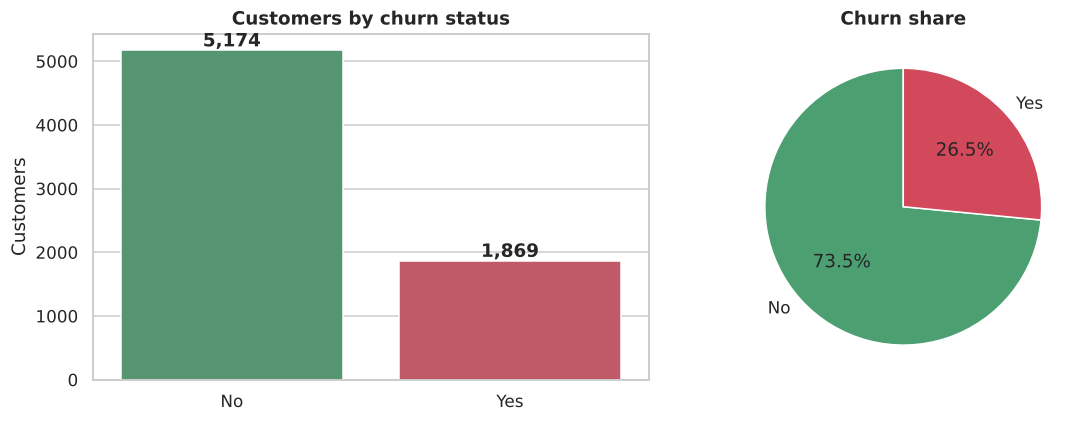

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
counts = df["Churn"].value_counts()
sns.barplot(x=counts.index, y=counts.values, ax=ax[0], palette=["#4C9F70", "#D1495B"])
for i, v in enumerate(counts.values): ax[0].text(i, v + 60, f"{v:,}", ha="center", fontweight="bold")
ax[0].set(title="Customers by churn status", xlabel="", ylabel="Customers")
ax[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90,
          colors=["#4C9F70", "#D1495B"], wedgeprops={"edgecolor": "white"})
ax[1].set_title("Churn share")
plt.tight_layout(); plt.show()

### 5.2 Distributions of numeric variables (histograms + KDE)

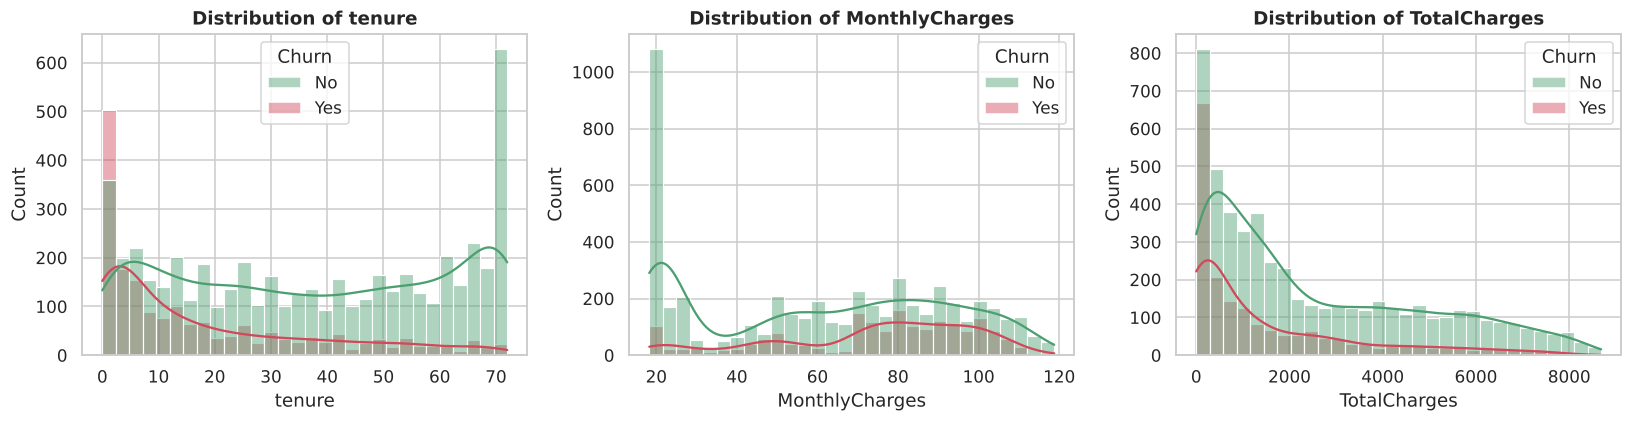

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, num_cols):
    sns.histplot(data=df, x=c, hue="Churn", kde=True, bins=30, ax=ax, palette=["#4C9F70", "#D1495B"], alpha=.45)
    ax.set_title(f"Distribution of {c}")
plt.tight_layout(); plt.show()

**Reading the charts.** Churners are concentrated in the **first few months** of tenure (a sharp spike near zero), while retained customers show a second cluster at the 70+ month mark (loyal long-term base). Monthly charges for churners shift toward the **$70-$100** range.

### 5.3 Box plots: spread and medians by churn

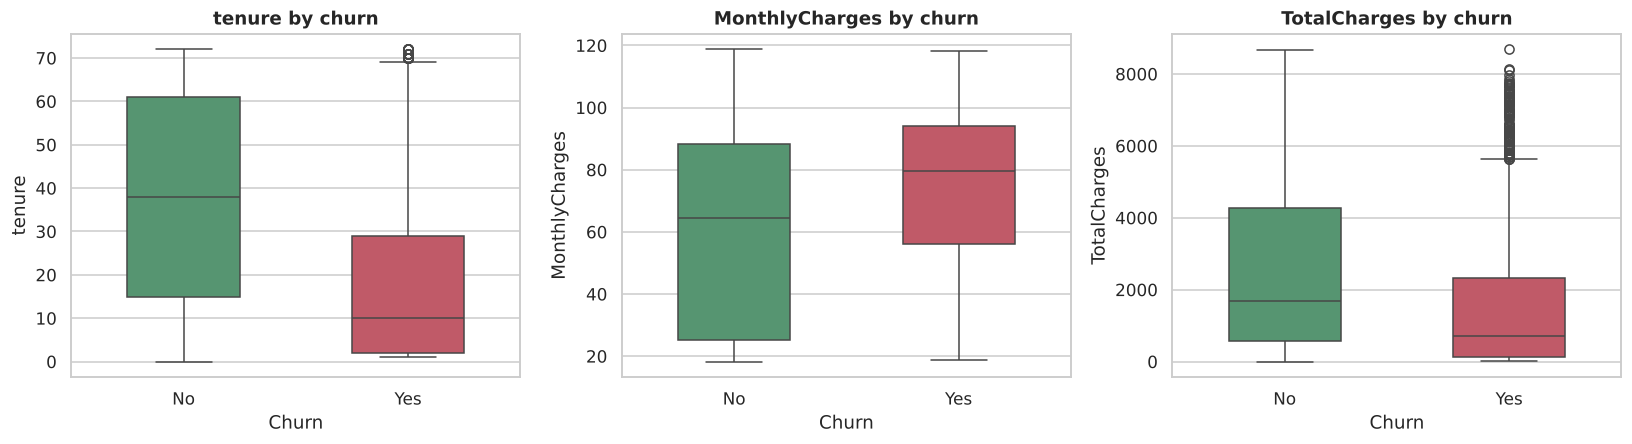

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, c in zip(axes, num_cols):
    sns.boxplot(data=df, x="Churn", y=c, ax=ax, palette=["#4C9F70", "#D1495B"], width=.5)
    ax.set_title(f"{c} by churn")
plt.tight_layout(); plt.show()

### 5.4 Churn rate by contract, internet service and payment method

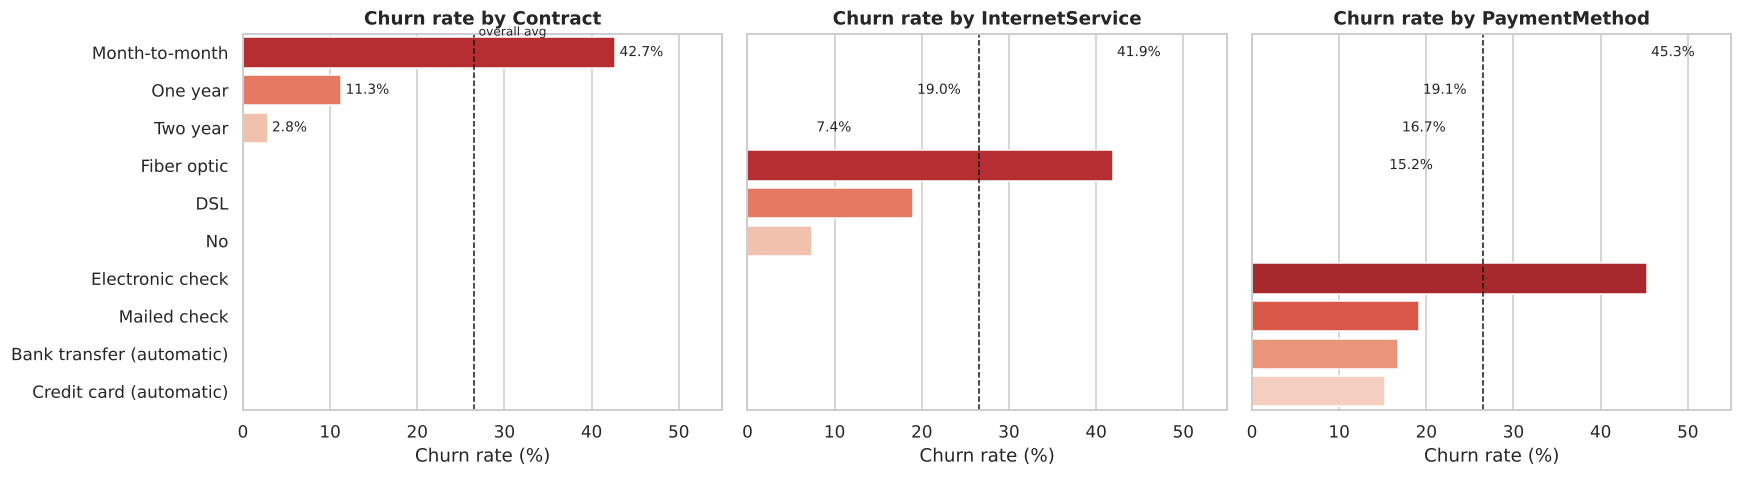

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, c in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    r = df.groupby(c, observed=True)["ChurnFlag"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=r.values, y=r.index.astype(str), ax=ax, palette="Reds_r", orient="h")
    for i, v in enumerate(r.values): ax.text(v + .5, i, f"{v:.1f}%", va="center", fontsize=9)
    ax.axvline(churn_rate*100, color="k", ls="--", lw=1); ax.set(title=f"Churn rate by {c}", xlabel="Churn rate (%)", ylabel="")
    ax.set_xlim(0, 55)
axes[0].text(churn_rate*100 + .5, -.45, "overall avg", fontsize=8)
plt.tight_layout(); plt.show()

### 5.5 Line chart: churn rate across customer lifetime

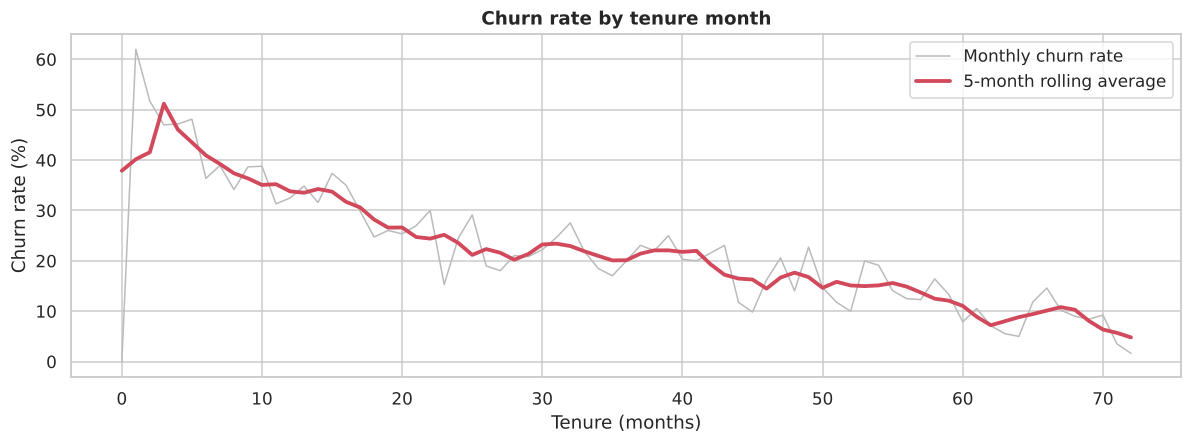

In [18]:
by_t = df.groupby("tenure")["ChurnFlag"].agg(["mean", "size"]).reset_index()
by_t["smooth"] = by_t["mean"].rolling(5, center=True, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(by_t["tenure"], by_t["mean"]*100, color="#bbb", lw=1, label="Monthly churn rate")
ax.plot(by_t["tenure"], by_t["smooth"]*100, color="#D1495B", lw=2.5, label="5-month rolling average")
ax.set(title="Churn rate by tenure month", xlabel="Tenure (months)", ylabel="Churn rate (%)"); ax.legend()
plt.tight_layout(); plt.show()

**Reading the chart.** Churn risk is highest at the very start of the customer relationship and falls steadily with tenure. The **first year is the critical retention window**.

### 5.6 Scatter plot: tenure vs. monthly charges

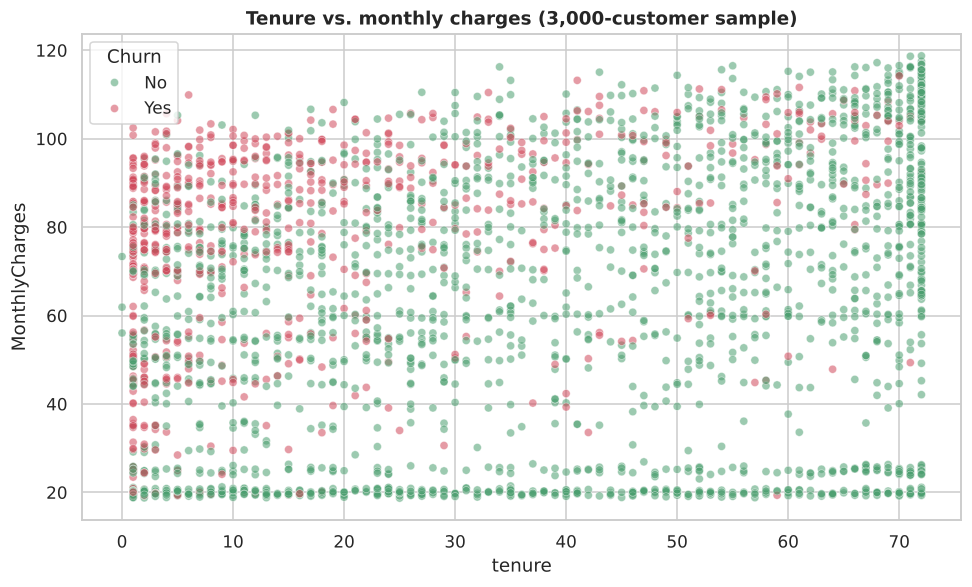

In [19]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=df.sample(3000, random_state=42), x="tenure", y="MonthlyCharges", hue="Churn",
                palette=["#4C9F70", "#D1495B"], alpha=.55, s=28, ax=ax)
ax.set_title("Tenure vs. monthly charges (3,000-customer sample)"); plt.tight_layout(); plt.show()

**Reading the chart.** Red points (churners) cluster in the **top-left**: short tenure, high monthly bill. Long-tenure, low-bill customers are rarely lost.

### 5.7 Heatmap: contract × internet service interaction

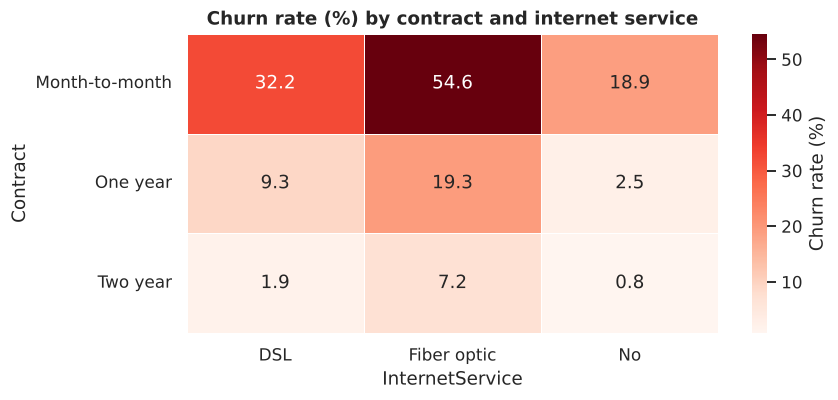

In [20]:
pivot = df.pivot_table(index="Contract", columns="InternetService", values="ChurnFlag", aggfunc="mean", observed=True) * 100
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Churn rate (%)"}, ax=ax, linewidths=.5)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_title("Churn rate (%) by contract and internet service"); plt.tight_layout(); plt.show()

### 5.8 Add-on services and protective effects

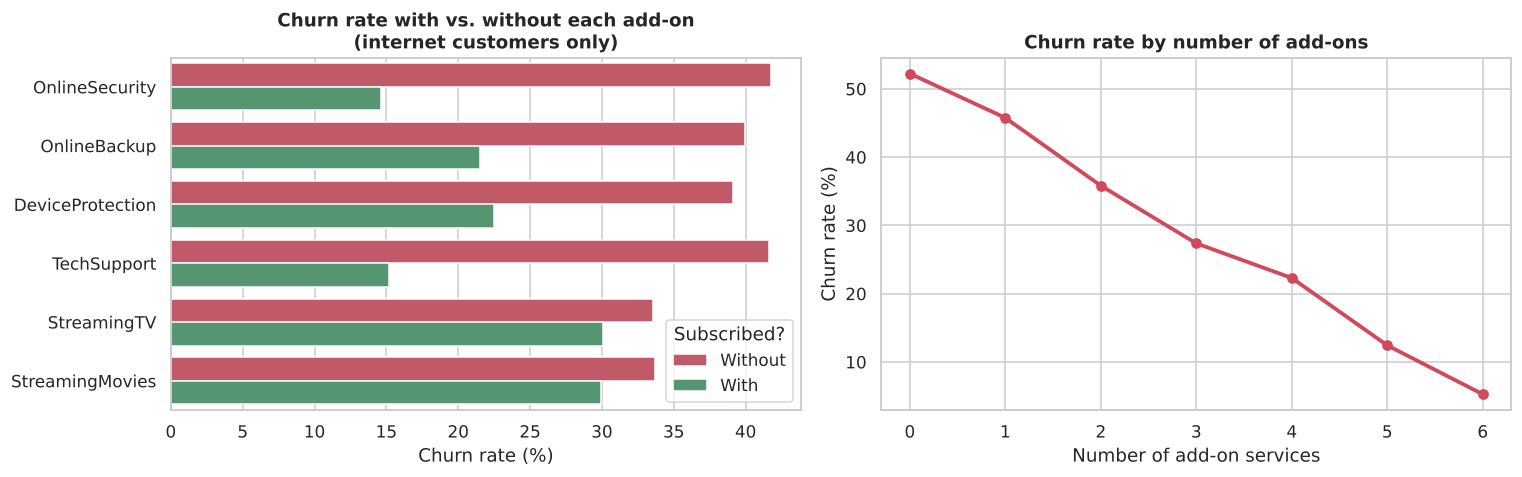

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
rows = []
for c in addon_cols:
    r = df[df.InternetService != "No"].groupby(c, observed=True)["ChurnFlag"].mean() * 100
    rows.append({"service": c, "Without": r["No"], "With": r["Yes"]})
addon_df = pd.DataFrame(rows).melt("service", var_name="Subscribed?", value_name="churn")
sns.barplot(data=addon_df, x="churn", y="service", hue="Subscribed?", palette=["#D1495B", "#4C9F70"], ax=axes[0])
axes[0].set(title="Churn rate with vs. without each add-on\n(internet customers only)", xlabel="Churn rate (%)", ylabel="")

n = df[df.InternetService != "No"].groupby("NumAddOns")["ChurnFlag"].mean() * 100
axes[1].plot(n.index, n.values, marker="o", color="#D1495B", lw=2.5)
axes[1].set(title="Churn rate by number of add-ons", xlabel="Number of add-on services", ylabel="Churn rate (%)")
plt.tight_layout(); plt.show()

### 5.9 Correlation heatmap (numeric + one-hot key categoricals)

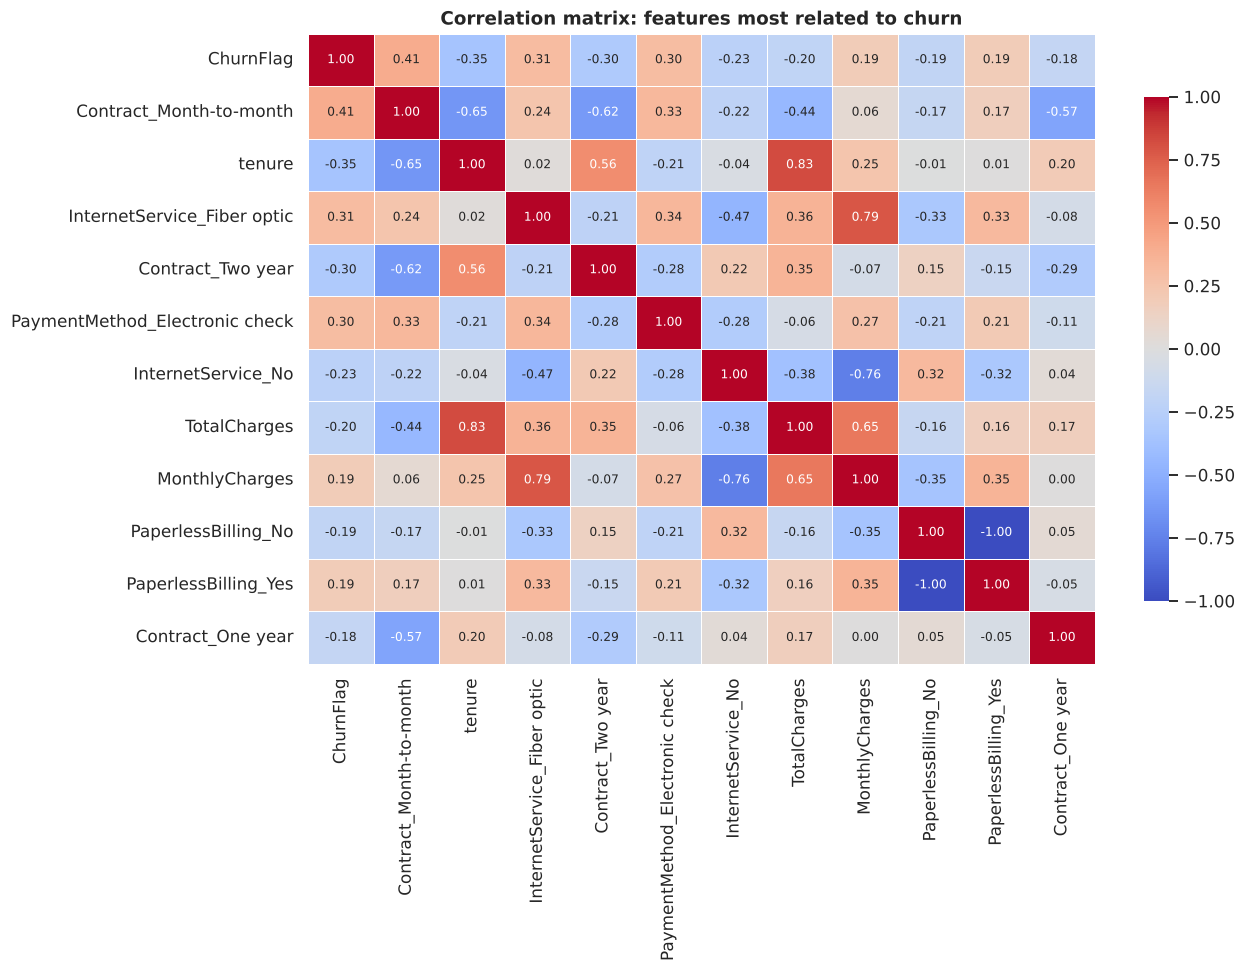

In [22]:
enc = pd.get_dummies(df[["Contract", "InternetService", "PaymentMethod", "PaperlessBilling", "SeniorCitizen"]], drop_first=False).astype(int)
mat = pd.concat([df[["tenure", "MonthlyCharges", "TotalCharges", "NumAddOns", "ChurnFlag"]], enc], axis=1).corr()
top = mat["ChurnFlag"].abs().sort_values(ascending=False).head(12).index
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(mat.loc[top, top], annot=True, fmt=".2f", annot_kws={"size": 8}, cmap="coolwarm", center=0, ax=ax, linewidths=.4, cbar_kws={"shrink": .8})
ax.set_title("Correlation matrix: features most related to churn"); plt.tight_layout(); plt.show()

### 5.10 Customer segments: where is churn concentrated?

,customers,churn_rate,avg_monthly,churned,share_of_all_churners
Segment,,,,,
1-2 year contract,3168,6.8%,$62.76,214,11.4%
"Month-to-month, 13+ months",1881,33.5%,$75.07,631,33.8%
"Month-to-month, first year",1994,51.4%,$58.22,1024,54.8%


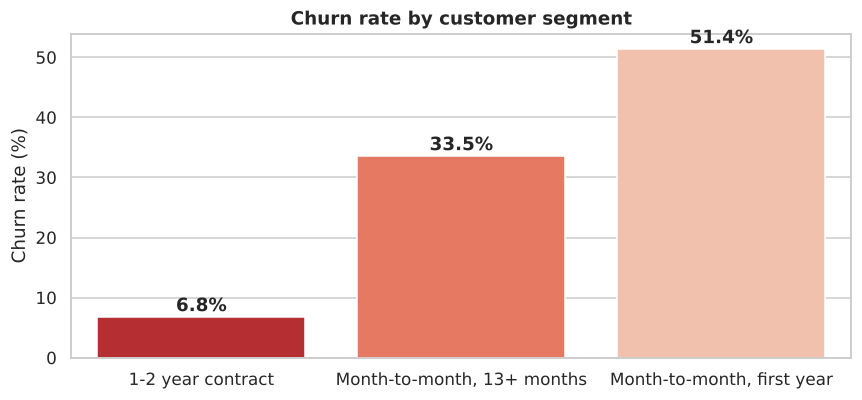

In [23]:
seg = (df.assign(Segment=np.where((df.Contract == "Month-to-month") & (df.tenure <= 12), "Month-to-month, first year",
                  np.where(df.Contract == "Month-to-month", "Month-to-month, 13+ months", "1-2 year contract")))
         .groupby("Segment", observed=True)
         .agg(customers=("ChurnFlag", "size"), churn_rate=("ChurnFlag", "mean"),
              avg_monthly=("MonthlyCharges", "mean"), churned=("ChurnFlag", "sum")))
seg["share_of_all_churners"] = seg["churned"] / seg["churned"].sum()
display(seg.style.format({"churn_rate": "{:.1%}", "avg_monthly": "${:.2f}", "share_of_all_churners": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.barplot(x=seg.index, y=seg["churn_rate"]*100, ax=ax, palette="Reds_r")
for i, v in enumerate(seg["churn_rate"]*100): ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontweight="bold")
ax.set(title="Churn rate by customer segment", xlabel="", ylabel="Churn rate (%)"); plt.tight_layout(); plt.show()

## 6. Key Insights, Interpretations & Recommendations

### Methodology recap
Loaded the IBM Telco dataset (7,043 × 21) → inspected structure, types, nulls, duplicates and label consistency → found a hidden data-type problem (`TotalCharges` stored as text with 11 blank values, all tenure-0 customers) and fixed it with a logical imputation → standardised labels → checked outliers (none) → engineered tenure bands and add-on counts → analysed with group statistics, chi-square / Cramér's V, Mann-Whitney U tests and correlations → visualised the results.

### Key findings
| # | Finding | Evidence |
|---|---|---|
| 1 | **Overall churn is high.** About 26.5% of customers churned, representing roughly 30% of monthly recurring revenue. | §4.1 |
| 2 | **Contract type is the strongest single driver.** Month-to-month customers churn at ~43%, versus ~11% (1-year) and ~3% (2-year). | §5.4 |
| 3 | **The first year is the danger zone.** Customers with 0-12 months tenure churn at ~47%, falling to ~10% after 4 years. Median tenure of churners is 10 months vs. 38 months. | §5.5, §4.2 |
| 4 | **Fiber-optic customers churn at ~42%** versus ~19% for DSL, even though fiber is the premium product, which suggests a price-to-value or service-quality problem. | §5.4, §5.7 |
| 5 | **Electronic-check payers churn at ~45%**, versus ~15-17% for automatic bank/credit-card payments. Paperless-billing customers also churn about twice as often as paper-billing ones (~34% vs ~16%). | §5.4, §4.3 |
| 6 | **Support add-ons are protective.** Among internet customers, those with Online Security or Tech Support churn at roughly a third of the rate of those without (~15% vs ~42%), and churn falls as the number of add-ons rises. Add-on subscribers may simply be more engaged customers (see limitations). | §5.8 |
| 7 | **Higher bills accompany churn.** Churners pay more per month (median ~$80 vs ~$64). | §4.2, §5.6 |
| 8 | **Demographic effects are mixed.** Seniors (42%), customers without partners or dependents churn more. **Gender has no meaningful effect.** | §4.3 |
| 9 | **Highest-risk segment:** month-to-month customers in their first year churn at ~51% and account for ~55% of all churners (from only ~28% of customers). Customers on 1-2 year contracts churn at ~7%. | §5.10 |

### Recommendations
1. **Convert month-to-month customers to annual contracts**, using discounts or perks, especially in months 3-12 when the risk is highest.
2. **Build a first-year onboarding and check-in programme** (welcome calls, early service-quality checks, a 90-day satisfaction touchpoint).
3. **Bundle or trial Online Security and Tech Support** for new internet customers. They are associated with much lower churn.
4. **Investigate fiber-optic service quality and pricing.** Run a satisfaction survey, check outage and speed complaints, and consider price-lock offers.
5. **Move customers to automatic payment** (small credit or bill discount), since electronic-check payers are by far the least stable.
6. **Target retention spend by value and risk:** use the high-risk segments above and prioritise those with higher monthly bills.

### Limitations & next steps
- The data is a **single snapshot**, so we can show association but not causation. Add-on subscribers may simply be more engaged customers.
- Churn is observed over one period with no time dimension, so seasonality and trends cannot be examined.
- There is no data on complaints, usage, network quality or competitor offers, which are likely important drivers.
- **Next steps:** build a predictive model (logistic regression / gradient boosting) with class-imbalance handling and customer-lifetime-value weighting, then run A/B tests of the retention offers above.